# Operação Pega-Laranja: Investigação de Redes e Fraudes com PaySim

Este projeto simula uma investigação de **Prevenção à Fraude e Anti-Lavagem de Dinheiro (AML)** em uma instituição financeira, utilizando dados transacionais do simulador acadêmico PaySim.

### Hipótese Inicial da Investigação:
1. **Concentração:** As fraudes não ocorrem aleatoriamente; elas se concentram em tipos específicos de operações de alta liquidez (como transferências e saques rápidos).

2. **Modus Operandi:** Os criminosos utilizam contas intermediárias (contas laranjas / *mule accounts*) para movimentar valores elevados e esvaziar o saldo da origem de forma integral antes que o bloqueio sistêmico atue.

## 1. Visão Geral e Auditoria de Dados (Data Quality)
Antes de iniciar qualquer análise preditiva ou busca de padrões, é regra fundamental de engenharia de dados realizar um **Teste de Sanidade** para verificar o volume global e garantir que a base não possui falhas estruturais ou valores corrompidos (`NULL`).

In [7]:
import sqlite3
import pandas as pd 

# 1. Conectando ao banco de dados 
DB_FILE = 'paysim_banco.db'
conn = sqlite3.connect(DB_FILE)

print(" --- INICIANDO A ANÁLISE EXPLORATÓRIA (EDA) ---- \n")

# 2. Query 
# 1: Visão Geral e Proporção de Fraude
#Contagem do total de linhas, total de fraude e calculo do %
query_visao_geral = """
SELECT
    COUNT (*) AS total_transacoes,
    SUM (isFraud) AS total_fraudes,
    COUNT (*) - SUM(isFraud) AS total_legitimas,
    ROUND ((CAST(SUM(isFraud) AS FLOAT) / COUNT (*)) * 100, 4) AS pct_fraude
FROM transacoes;
"""

# pd.read_sql_query executa a query SQL e traz o resultado formatado em DataFrame
df_visao_geral = pd.read_sql_query(query_visao_geral, conn)
print("1. Visão Geral do Volume de Transações:")
display(df_visao_geral)

# 3. Query 
# 2: Auditoria de Valores Nulos (Data Quality Check)
# Verificando se existe algum buraco ou dado nulo nas colunas principais
query_audotiria_nulos = """
SELECT
    SUM(CASE WHEN step IS NULL THEN 1 ELSE 0 END) AS nulos_step,
    SUM(CASE WHEN type IS NULL THEN 1 ELSE 0 END) AS nulos_type,
    SUM(CASE WHEN amount IS NULL THEN 1 ELSE 0 END) AS nulos_amount,
    SUM(CASE WHEN nameOrig IS NULL THEN 1 ELSE 0 END) AS nulos_nameOrig,
    SUM(CASE WHEN isFraud IS NULL THEN 1 ELSE 0 END) AS nulos_isFraud
FROM transacoes;
"""

df_nulos = pd.read_sql_query(query_audotiria_nulos, conn)
print("\n 2. Auditoria de Dados Nulos (Data Quality):")
display(df_nulos)

 --- INICIANDO A ANÁLISE EXPLORATÓRIA (EDA) ---- 

1. Visão Geral do Volume de Transações:


,total_transacoes,total_fraudes,total_legitimas,pct_fraude
0,6362620,8213,6354407,0.1291



 2. Auditoria de Dados Nulos (Data Quality):


,nulos_step,nulos_type,nulos_amount,nulos_nameOrig,nulos_isFraud
0,0,0,0,0,0


* **Volume analisado:** Mais de 6,3 milhões de transações.
* **Taxa base de fraude:** Evento altamente desbalanceado (~0,13%), refletindo o cenário real do mercado financeiro.

## 2. Mapeamento de Risco: Onde as Fraudes se Concentram?
Nesta etapa, cruzamos os dados para descobrir quais tipos de transação (`type`) concentram as tentativas de fraude. 

In [8]:
# Query 3: Distribuição de Fraudes por Tipo de Transação (type)
query_fraude_por_tipo = """
SELECT 
    type AS tipo_transacao,
    COUNT(*) AS total_operacoes,
    SUM(isFraud) AS qtd_fraudes,
    ROUND((CAST(SUM(isFraud) AS FLOAT) / COUNT(*)) * 100, 2) AS taxa_fraude_pct
FROM transacoes
GROUP BY type
ORDER BY qtd_fraudes DESC;
"""

df_fraude_tipo = pd.read_sql_query(query_fraude_por_tipo, conn)
print(" 3. Onde estão as fraudes? (Análise por Tipo de Transação):")
display(df_fraude_tipo)

 3. Onde estão as fraudes? (Análise por Tipo de Transação):


,tipo_transacao,total_operacoes,qtd_fraudes,taxa_fraude_pct
0,CASH_OUT,2237500,4116,0.18
1,TRANSFER,532909,4097,0.77
2,CASH_IN,1399284,0,0.00
3,DEBIT,41432,0,0.00
4,PAYMENT,2151495,0,0.00


**Achado da Investigação:** 
100% dos eventos fraudulentos estão restritos a apenas duas categorias: **TRANSFER** e **CASH_OUT**. Outras operações cotidianas (como pagamentos e depósitos) apresentam incidência nula de golpes, servindo de filtro inicial para regras de bloqueio.

## 3. Análise Comportamental: O Padrão de Esvaziamento de Saldo
Para entender o comportamento do fraudador, analisamos o impacto financeiro (valor médio) e o comportamento do saldo da conta origem após a operação (`newbalanceOrig = 0`).

In [9]:
# Query #4: Comportamento de Esvaziamento de Saldo (Zero Balance)
# Verificando se as fraudes limpam totalmente o saldo da conta origem em TRANSFER e CASH_OUT
query_esvaziamento = """
SELECT 
    isFraud,
    COUNT(*) AS total_transacoes,
    ROUND(AVG(amount), 2) AS valor_medio_transacao,
    SUM(CASE WHEN newbalanceOrig = 0 AND amount > 0 THEN 1 ELSE 0 END) AS qtd_contas_zeradas
FROM transacoes
WHERE type IN ('TRANSFER', 'CASH_OUT')
GROUP BY isFraud;
"""

df_esvaziamento = pd.read_sql_query(query_esvaziamento, conn)
print("4. Análise Comportamental: O Esvaziamento de Saldo (TRANSFER e CASH_OUT):")
display(df_esvaziamento)

4. Análise Comportamental: O Esvaziamento de Saldo (TRANSFER e CASH_OUT):


,isFraud,total_transacoes,valor_medio_transacao,qtd_contas_zeradas
0,0,2762196,314115.5,2488603
1,1,8213,1467967.3,8037


**Conclusão da Análise:**
* O valor médio das transações fraudulentas é **quatro vezes superior** ao das transações legítimas, provando que os golpistas buscam alvos de alto impacto.
* Quase **98% das fraudes** deixam o saldo da conta origem estritamente zerado, confirmando o comportamento de "aspirador de pó" das contas laranjas.

## 4. Visualização de Redes: Mapeando Contas Laranjas
Tabelas e números são essenciais, mas a visualização de redes (*Graph Analytics*) permite enxergar a teia de conexões entre as contas envolvidas.

Através de um grafo direcionado, mapeamos o fluxo de capital entre as contas de origem e destino nas transações suspeitas, evidenciando as cadeias de repasse típicas de lavagem de dinheiro.

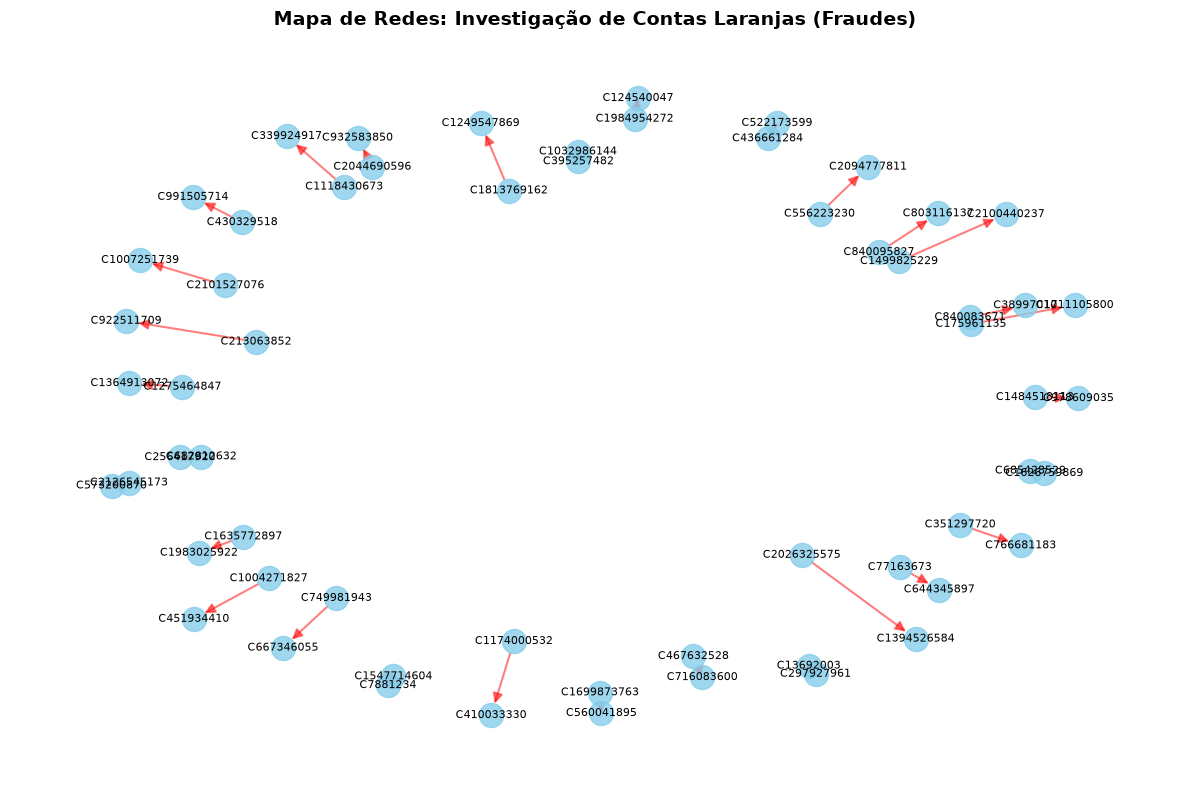

In [10]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# 1. Buscar uma amostra de transações fraudulentas do tipo TRANSFER e CASH_OUT
query_grafo = """
SELECT nameOrig, nameDest, amount
FROM transacoes
WHERE isFraud = 1 AND type IN ('TRANSFER', 'CASH_OUT')
LIMIT 30;  -- Limitamos a 30 para o grafo não ficar sobrecarregado visualmente
"""

df_grafo = pd.read_sql_query(query_grafo, conn)

# 2. Criar um grafo direcionado (as setas mostram a direção do dinheiro)
G = nx.DiGraph()

# 3. Adicionar as conexões (arestas) entre a conta origem (nameOrig) e a conta destino (nameDest)
for index, row in df_grafo.iterrows():
    G.add_edge(row['nameOrig'], row['nameDest'], weight=row['amount'])

# 4. Configurar a visualização do gráfico
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.15, seed=42) # Organiza os nós de forma orgânica

# Desenhar os nós (as contas) e as arestas (as transferências)
nx.draw_networkx_nodes(G, pos, node_size=300, node_color='skyblue', alpha=0.8)
nx.draw_networkx_edges(G, pos, width=1.5, alpha=0.5, edge_color='red', arrows=True, arrowsize=15)
nx.draw_networkx_labels(G, pos, font_size=8, font_family='sans-serif')

plt.title("Mapa de Redes: Investigação de Contas Laranjas (Fraudes)", fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()

# Salvar a imagem com alta resolução na pasta do projeto
plt.savefig('mapa_redes_fraudes.png', dpi=300, bbox_inches='tight')

plt.show()

## 5. Conclusão e Recomendações de Negócio

### Resumo dos Achados
A investigação conduzida nos dados transacionais permitiu mapear o comportamento-alvo dos fraudadores:
1. **Concentração de Risco:** 100% das fraudes ocorrem via **TRANSFER** e **CASH_OUT**.
2. **Impacto Financeiro:** As fraudes movimentam valores médios expressivamente maiores do que as operações legítimas.
3. **Modus Operandi:** O esvaziamento integral do saldo de origem (`newbalanceOrig = 0`) é a assinatura comportamental mais forte das contas laranjas (*mule accounts*).

### Recomendações Práticas para a Equipe de Risco
* **Regra de Bloqueio Preventivo:** Implementar alertas automáticos ou *hold* temporário de segurança para transferências de alto valor (`TRANSFER`) seguidas imediatamente de saques totais (`CASH_OUT`).
* **Monitoramento de Redes:** Utilizar análise de grafos para identificar nós centrais que recebem fluxos pulverizados e os repassam rapidamente.

### Próximos Passos (Evolução do Projeto)
* Construção de um modelo preditivo de Machine Learning utilizando as *features* de comportamento de saldo e velocidade de transação para pontuar o risco em tempo real.